# Исследование надёжности заёмщиков

Заказчик — кредитный отдел банка. Нужно разобраться, влияет ли семейное положение и количество детей клиента на факт погашения кредита в срок. Входные данные от банка — статистика о платёжеспособности клиентов.

Результаты исследования будут учтены при построении модели **кредитного скоринга** — специальной системы, которая оценивает способность потенциального заёмщика вернуть кредит банку.

## Шаг 1. Для начала, открою базу данных, ознакомлюсь с информацией в ней представленной, изучу значение столбцов из технического задания.

In [ ]:
import pandas as pd

'''try:
    df = pd.read_csv('bank_scoring_data.csv')
except Exception as e:
    print(e)
    df = pd.read_csv('/datasets/data.csv')'''

df = pd.read_csv('bank_scoring_data.csv')
display(df.head(10))
df.info()

,children,days_employed,dob_years,education,education_id,family_status,family_status_id,gender,income_type,debt,total_income,purpose
0,1,-8437.673028,42,высшее,0,женат / замужем,0,F,сотрудник,0,253875.639453,покупка жилья
1,1,-4024.803754,36,среднее,1,женат / замужем,0,F,сотрудник,0,112080.014102,приобретение автомобиля
2,0,-5623.422610,33,Среднее,1,женат / замужем,0,M,сотрудник,0,145885.952297,покупка жилья
3,3,-4124.747207,32,среднее,1,женат / замужем,0,M,сотрудник,0,267628.550329,дополнительное образование
4,0,340266.072047,53,среднее,1,гражданский брак,1,F,пенсионер,0,158616.077870,сыграть свадьбу
5,0,-926.185831,27,высшее,0,гражданский брак,1,M,компаньон,0,255763.565419,покупка жилья
6,0,-2879.202052,43,высшее,0,женат / замужем,0,F,компаньон,0,240525.971920,операции с жильем
7,0,-152.779569,50,СРЕДНЕЕ,1,женат / замужем,0,M,сотрудник,0,135823.934197,образование
8,2,-6929.865299,35,ВЫСШЕЕ,0,гражданский брак,1,F,сотрудник,0,95856.832424,на проведение свадьбы
9,0,-2188.756445,41,среднее,1,женат / замужем,0,M,сотрудник,0,144425.938277,покупка жилья для семьи


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21525 entries, 0 to 21524
Data columns (total 12 columns):
children            21525 non-null int64
days_employed       19351 non-null float64
dob_years           21525 non-null int64
education           21525 non-null object
education_id        21525 non-null int64
family_status       21525 non-null object
family_status_id    21525 non-null int64
gender              21525 non-null object
income_type         21525 non-null object
debt                21525 non-null int64
total_income        19351 non-null float64
purpose             21525 non-null object
dtypes: float64(2), int64(5), object(5)
memory usage: 2.0+ MB


**Вывод**

    Размеры предоставленной нам базы - 21525 строк, 12 столбцов. Данные представлены в виде чисел (типы "int" и "float"), также имеются текстовые поля (тип "object").
    
    Ознакомившись с первыми 10 строками таблицы и общей информацией о ней, а также с заданиями и описанием базы, можно сделать следующие выводы: в значениях столбцов "days_employed" и "total_income" имеются пропуски и количество этих пропусков в этих столбцах одинаково, ознакомившись с описанием этих столбцов, можно предположить, что пропуски скорее всего связаны с тем, что данные заёмщики официально не работают, при этом они могут быть - самозанятые или иметь свой бизнес. В своём исследовании я проверю есть ли связь факта наличия пропусков в данных столбцах и определённой категории столбца "income_type".
    
    Изучив внимательно задания, можно предположить, что для наших исследований наверняка понадобятся значения следующих столбцов:  "children", "family_status", "family_status_id", "debt", "total_income", "purpose".
    
    Отсутствие значений в столбце "days_employed" не повлияет на результат наших исследований, а вот отсутствие значений в столбце "total_income", повлияет, так как придётся сократить выборку на количество этих пропусков при исследовании одной из гипотез задания (Есть ли зависимость между уровнем дохода и возвратом кредита в срок?). Выборка сократиться не существенно и для решения поставленной задачи будем считать её достаточной (если только все эти пропуска не будут относиться к одной категории), в ином случае придётся запросить дополнительную информацию по этим пропускам у заказчика, у администратора БД.
    
    Также видим, что в столбце "days_employed" значения не целые и также есть отрицательные, к тому же значение в 4-й строке явно ошибочно так как содержит 340266 дней, а это около 1000 лет стажа. Пока что мне не понятны причины этого, возможно это автоматически считаемая разница (которая была некорректно посчитана) между датой начала и окончания трудовой деятельности на определённом месте работы, а если таких периодов несколько, соответственно подсчитана сумма таких периодов. В своём исследовании я попробую разобраться с этим. При необходимости, можно запросить подробные инструкции по этому столбцу. Можно попробовать запросить эту информацию у того кто предоставил базу, у администратора данной БД (база данных), у того кто заносит данные в БД. Хотя, согласно заданиям, нам этот столбец и не будет нужен, но для наглядности неплохо бы понимать количество лет и месяцев трудового стажа заёмщика, возможно нам удастся усмотреть новые взаимосвязи и сделать более информативные выводы в рамках поставленных нам задач. 

## Шаг 2. Предобработка данных

### Обработка пропусков

В предъидущем пункте методом "info()" удалось выяснить, что пропуски имеются по двум столбцам - 'total_income', 'days_employed'
Применю метод ".isna()" и внимательно рассмотрю строки с пропусками.

In [10]:
display(df[df['total_income'].isna()].head(5)) # сделаем выборку строк где есть пропуски в столбце 'total_income'

,children,days_employed,dob_years,education,education_id,family_status,family_status_id,gender,income_type,debt,total_income,purpose
12,0,NaN,65,среднее,1,гражданский брак,1,M,пенсионер,0,NaN,сыграть свадьбу
26,0,NaN,41,среднее,1,женат / замужем,0,M,госслужащий,0,NaN,образование
29,0,NaN,63,среднее,1,Не женат / не замужем,4,F,пенсионер,0,NaN,строительство жилой недвижимости
41,0,NaN,50,среднее,1,женат / замужем,0,F,госслужащий,0,NaN,сделка с подержанным автомобилем
55,0,NaN,54,среднее,1,гражданский брак,1,F,пенсионер,1,NaN,сыграть свадьбу


In [13]:
df.isna().sum() # считаем количество пропусков

children               0
days_employed       2174
dob_years              0
education              0
education_id           0
family_status          0
family_status_id       0
gender                 0
income_type            0
debt                   0
total_income        2174
purpose                0
dtype: int64

In [12]:
display(df[df['days_employed'].isna()].head(5)) # сделаем выборку строк где есть пропуски в столбце 'days_employed'

,children,days_employed,dob_years,education,education_id,family_status,family_status_id,gender,income_type,debt,total_income,purpose
12,0,NaN,65,среднее,1,гражданский брак,1,M,пенсионер,0,NaN,сыграть свадьбу
26,0,NaN,41,среднее,1,женат / замужем,0,M,госслужащий,0,NaN,образование
29,0,NaN,63,среднее,1,Не женат / не замужем,4,F,пенсионер,0,NaN,строительство жилой недвижимости
41,0,NaN,50,среднее,1,женат / замужем,0,F,госслужащий,0,NaN,сделка с подержанным автомобилем
55,0,NaN,54,среднее,1,гражданский брак,1,F,пенсионер,1,NaN,сыграть свадьбу


Очень похоже на то, что пропуска в столбцах 'total_income', 'days_employed' полностью совпадают по номерам строк.
Проверю данное предположение.

In [8]:
display(len(df[df['days_employed'].isna() & df['total_income'].isna()])) # считаем строки где есть пропуски 
                                                                        # и в столбце 'days_employed' и в столбце 'total_income'

2174

Предположение подтвердилось пропуск по данным столбцам находятся в одних и тех же строках.

Трудовой стаж и доход это количественные переменные. Пропуски в таких переменных, как правило, заполняют характерными значениями. Это значения, характеризующие состояние выборки. Обычно это среднее арифметическое или медиана. 

Найдём медианные значения дохода для каждой категории одновременно подсчитав количество чел в категориях.

In [35]:
df.groupby('income_type').agg({'total_income': ['count', 'median']}).reset_index()

income_type total_income               
                          count         median
0      безработный            2  131339.751676
1        в декрете            1   53829.130729
2      госслужащий         1312  150447.935283
3        компаньон         4577  172357.950966
4        пенсионер         3443  118514.486412
5  предприниматель            1  499163.144947
6        сотрудник        10014  142594.396847
7          студент            1   98201.625314

Разброс по значениям дохода меньше если рассматривать каждую категорию в отдельности, поэтому принимаю решение заменить пропуски медианными значениями в зависимости от категории.

Прежде чем сделать это, посмотрим ещё по каким категориям и в каком количестве допущены пропуски.

In [46]:
df['income_type'].value_counts() # считаем какие категории вообще есть и сколько в них заемщиков
# df.notna().sum() # противоположность isna,  ту же информацию содержит info

сотрудник          11119
компаньон           5085
пенсионер           3856
госслужащий         1459
безработный            2
предприниматель        2
студент                1
в декрете              1
Name: income_type, dtype: int64

In [ ]:
# df[df['total_income'].isna()]['income_type'].value_counts(normalize=True) # считаем по каким категориям заемщиков сколько пропусков в долях
df[df['total_income'].isna()]['income_type'].value_counts() # считаем по каким категориям заемщиков сколько пропусков

сотрудник          1105
компаньон           508
пенсионер           413
госслужащий         147
предприниматель       1
Name: income_type, dtype: int64

In [32]:
df.isna().mean() * 100 # считаем долю пропусков  столбцах %

children             0.000000
days_employed       10.099884
dob_years            0.000000
education            0.000000
education_id         0.000000
family_status        0.000000
family_status_id     0.000000
gender               0.000000
income_type          0.000000
debt                 0.000000
total_income        10.099884
purpose              0.000000
dtype: float64

видим случайность пропусков относительно столбца `income_type` 


In [ ]:
df['total_income'] = df.groupby('income_type')['total_income'].transform(lambda x : x.fillna(x.median())) # заменим оставшиеся 
                                                      # пропуски медианными значениями в зависимости от категории 'income_type'

df['days_employed'] = df.groupby('income_type')['days_employed'].transform(lambda x : x.fillna(x.median()))


**Вывод**

Пропуски в "total_income" не связаны с какой-то определённой категорией заёмщиков они равнораспределены. Поэтому будем считать их случайными.

Строки с пропусками в столбцах 'days_employed' и 'total_income' полностью совпадают.

Причина появления пропусков - мне не понятна, какой-то закономерности я не увидел. 

Пропуски в 'total_income', 'days_employed' заменил медианными значениями в зависимости от категории.

### Замена типа данных

Значения колонок 'total_income' и 'days_employed' типа 'float', преобразуем их в 'int'.

In [52]:
df['total_income'] = df['total_income'].astype('int') # преобразуем тип значений столбца total_income из float в int
df.info() # проверяем

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21525 entries, 0 to 21524
Data columns (total 12 columns):
children            21525 non-null int64
days_employed       21525 non-null float64
dob_years           21525 non-null int64
education           21525 non-null object
education_id        21525 non-null int64
family_status       21525 non-null object
family_status_id    21525 non-null int64
gender              21525 non-null object
income_type         21525 non-null object
debt                21525 non-null int64
total_income        21525 non-null int64
purpose             21525 non-null object
dtypes: float64(1), int64(6), object(5)
memory usage: 2.0+ MB


Добавим столбец 'years_employed' - количество полных лет стажа.

In [53]:
df['days_employed'] = abs(df['days_employed'].astype('int')) # преобразуем тип значений столбца 'days_employed' из float в положительный int
df['years_employed'] = df['days_employed'] // 365  # добавим новый столбец 'years_employed' и запишем туда количество 
                                                   # полных лет стажа, применив целочисленное деление
df.info() # проверяем

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21525 entries, 0 to 21524
Data columns (total 13 columns):
children            21525 non-null int64
days_employed       21525 non-null int64
dob_years           21525 non-null int64
education           21525 non-null object
education_id        21525 non-null int64
family_status       21525 non-null object
family_status_id    21525 non-null int64
gender              21525 non-null object
income_type         21525 non-null object
debt                21525 non-null int64
total_income        21525 non-null int64
purpose             21525 non-null object
years_employed      21525 non-null int64
dtypes: int64(8), object(5)
memory usage: 2.1+ MB


Изучим значения столбца 'days_employed', так как в первых строках я увидел одну ошибку - слишком большое значение.
Для начала сделаю сортировку по убыванию данных значений.

In [54]:
display(df.sort_values(by='days_employed', ascending=False).head(10)) # сортируем датафрейм по убыванию значений столбца 'days_employed' и выводим на экран

,children,days_employed,dob_years,education,education_id,family_status,family_status_id,gender,income_type,debt,total_income,purpose,years_employed
6954,0,401755,56,среднее,1,вдовец / вдова,2,F,пенсионер,0,176278,ремонт жилью,1100
10006,0,401715,69,высшее,0,Не женат / не замужем,4,F,пенсионер,0,57390,получение образования,1100
7664,1,401675,61,среднее,1,женат / замужем,0,F,пенсионер,0,126214,операции с жильем,1100
2156,0,401674,60,среднее,1,женат / замужем,0,M,пенсионер,0,325395,автомобили,1100
7794,0,401663,61,среднее,1,гражданский брак,1,F,пенсионер,0,48286,свадьба,1100
4697,0,401635,56,среднее,1,женат / замужем,0,F,пенсионер,0,48242,покупка недвижимости,1100
13420,0,401619,63,Среднее,1,гражданский брак,1,F,пенсионер,0,51449,сыграть свадьбу,1100
17823,0,401614,59,среднее,1,женат / замужем,0,F,пенсионер,0,152769,покупка жилья для сдачи,1100
10991,0,401591,56,среднее,1,в разводе,3,F,пенсионер,0,39513,получение дополнительного образования,1100
8369,0,401590,58,среднее,1,женат / замужем,0,F,пенсионер,0,175306,образование,1100


Значений с 1000 летним стажем уже много. Попробую прикинуть количество ошибочных значений, 
ошибочными буду считать те значения, где они будут больше (В - 14). Где В - это возраст заёмщика, 
а 14 это количество лет, полагая, что официальный трудовой стаж идёт с 14 лет минимум для России.
Также посмотрю в каких категориях заёмщиков эти ошибки есть и их количество по категориям.

In [55]:
display(df[df['years_employed'] > (df['dob_years'] - 14)]['years_employed'].count()) # подсчитаем количество ошибочных значений в столбце "стаж" 

3537

In [56]:
df[df['years_employed'] > (df['dob_years'] - 14)]['income_type'].value_counts() # подсчитаю количество строк 
# по каждой категории 'income_type' , удовлетворяющих условию - "если значение столбца 'years_employed' > В - 14 "

пенсионер      3446
сотрудник        62
компаньон        21
госслужащий       6
безработный       2
Name: income_type, dtype: int64

По результату видно, что "ошибки" встречаются, в основном, по пенсионерам - почти в 90 % случаях, и по безработным - два из двух, в остальных категориях доля ошибок менее 1 %. 
Ещё раз внимательно изучив выборку, могу предположить, что это какая-то закономерность, то есть ошибки не случайные, возмужно перепутаны единицы измерения. 
Можно предположить, что все "ошибочные" значения записаны не в днях, а например в часах, переведём их ещё раз в количество лет.
Проверим эту гипотезу на какой-нибудь любой строке, например 6954.

In [57]:
print( 'стаж заёмщика: ', df.loc[6954, 'days_employed'] / 24 / 365)
print('возраст заёмщика: ', df.loc[6954, 'dob_years'])

стаж заёмщика:  45.862442922374434
возраст заёмщика:  56


гипотеза не подтвердилась. стаж не может быть 46 лет если возраст заёмщика 56. 
Так как значения из этого столбца напрямую на наше исследование не повлияют, оставляем как есть.

**Вывод**

Я преобразовал тип значений столбца 'total_income' в целочисленный тип.

Столбец 'days_employed' я преобразовал в положительные целочисленные значения, добавил ещё один столбец 'years_employed' и записал туда количество полных лет стажа заёмщика, целочисленно разделив дни на 365. 

В итоге получилось, что у некоторых заёмщиков стаж ошибочный. 90 % ошибок обнаружилось в категории пенсионеры, по многим из них трудовой стаж получается около 1100 лет. 
Выявить закономерность таких ошибок не удалось, поэтому оставляем данный столбец без изменений.

### Обработка дубликатов

In [58]:
df.duplicated().sum() # считаем количество полных дубликатов

54

In [59]:
df = df.drop_duplicates().reset_index(drop = True) # удаляем полные дубликаты
df.info() # проверяем

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21471 entries, 0 to 21470
Data columns (total 13 columns):
children            21471 non-null int64
days_employed       21471 non-null int64
dob_years           21471 non-null int64
education           21471 non-null object
education_id        21471 non-null int64
family_status       21471 non-null object
family_status_id    21471 non-null int64
gender              21471 non-null object
income_type         21471 non-null object
debt                21471 non-null int64
total_income        21471 non-null int64
purpose             21471 non-null object
years_employed      21471 non-null int64
dtypes: int64(8), object(5)
memory usage: 2.1+ MB


In [60]:
df['education'] = df['education'].str.lower() # приводим столбец "education" в нижний регистр
df['education'].value_counts() # проверяем , смотрим какие уникальные значения и частоту их встречаемости

среднее                15188
высшее                  5251
неоконченное высшее      744
начальное                282
ученая степень             6
Name: education, dtype: int64

In [62]:
df['family_status'] = df['family_status'].str.lower() # приводим столбец "family_status" в нижний регистр
df['family_status'].value_counts() # проверяем

женат / замужем          12344
гражданский брак          4163
не женат / не замужем     2810
в разводе                 1195
вдовец / вдова             959
Name: family_status, dtype: int64

In [63]:
df['gender'] = df['gender'].str.lower() # приводим столбец "gender" в нижний регистр
df['gender'].value_counts() # проверим какие значения может принимать данный столбец

f      14189
m       7281
xna        1
Name: gender, dtype: int64

Заёмщиков женщин в два раза больше чем мужчин, и кто-то один не указал свой пол. Для нашего исследования это некритично.

После наших преобразований регистра текстовых значений, проверим ещё раз количество дубликатов.

In [64]:
df.duplicated().sum() # проверяем

17

In [65]:
df = df.drop_duplicates().reset_index(drop = True) # удаляем
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21454 entries, 0 to 21453
Data columns (total 13 columns):
children            21454 non-null int64
days_employed       21454 non-null int64
dob_years           21454 non-null int64
education           21454 non-null object
education_id        21454 non-null int64
family_status       21454 non-null object
family_status_id    21454 non-null int64
gender              21454 non-null object
income_type         21454 non-null object
debt                21454 non-null int64
total_income        21454 non-null int64
purpose             21454 non-null object
years_employed      21454 non-null int64
dtypes: int64(8), object(5)
memory usage: 2.1+ MB


Перейдём к столбцу - цели кредита. Изучим какие там значения и частоту их встречаемости.

In [66]:
df['purpose'].value_counts() # проверим какие значения может принимать данный столбец

свадьба                                   791
на проведение свадьбы                     768
сыграть свадьбу                           765
операции с недвижимостью                  675
покупка коммерческой недвижимости         661
операции с жильем                         652
покупка жилья для сдачи                   651
операции с коммерческой недвижимостью     650
жилье                                     646
покупка жилья                             646
покупка жилья для семьи                   638
строительство собственной недвижимости    635
недвижимость                              633
операции со своей недвижимостью           627
строительство жилой недвижимости          624
покупка недвижимости                      621
покупка своего жилья                      620
строительство недвижимости                619
ремонт жилью                              607
покупка жилой недвижимости                606
на покупку своего автомобиля              505
заняться высшим образованием      

Видим тут много неявных дубликатов - значений целей много, а самих целей 5 - 7 штук : проведение свадьбы, покупка недвижимости, ремонт жилья, покупка автомобиля, получение образования... Чтобы выделить их, применим стемминг и лемматизацию.

In [67]:
from nltk.stem import SnowballStemmer 
russian_stemmer = SnowballStemmer('russian') # импортируем необходимые библиотеки

In [68]:
purpose_stem = df['purpose'].unique() # создам новую переменную, а в неё запишу массив с уникальными значениями столбца 'purpose'
for value in purpose_stem:
    print(russian_stemmer.stem(value)) # с помощью цикла применяем к каждому элементу данного массива метод "russian_stemmer.stem"

покупка жил
приобретение автомобил
дополнительное образован
сыграть свадьб
операции с жил
образован
на проведение свадьб
покупка жилья для сем
покупка недвижим
покупка коммерческой недвижим
покупка жилой недвижим
строительство собственной недвижим
недвижим
строительство недвижим
на покупку подержанного автомобил
на покупку своего автомобил
операции с коммерческой недвижим
строительство жилой недвижим
жил
операции со своей недвижим
автомоб
заняться образован
сделка с подержанным автомобил
получение образован
автомобил
свадьб
получение дополнительного образован
покупка своего жил
операции с недвижим
получение высшего образован
свой автомобил
сделка с автомобил
профильное образован
высшее образован
покупка жилья для сдач
на покупку автомобил
ремонт жил
заняться высшим образован


Данный метод вернул нам основы слов входящих в значения 'purpose'. 
Внимательно их изучив, я заметил некоторые "осечки" , например, основу слова жильё он вернул где-то как "жил", а где-то "жилья".
Конечно это не критично в нашем случае и можно с этим работать дальше. Но посмотрим, что нам может дать лемматизация.

**Вывод**

Полных дубликатов сначала было 54 штуки, я их удалил.
Далее я изучил уникальные значения всех столбцов, привёл к единообразию - текстовые значения - перевел в нижний регистр.
Ещё раз проверил дубликаты, нашёл ещё 17 штук, удалил их тоже. Таким образом, с помощью изученных способов, мне удалось выявить дубликаты и удалить их.

С помощью ".value_counts()" удалось определить неявные дубликаты в столбце - цель кредита. 
С помощью стемминга удалось выявить основы слов в столбце 'purpose'. 
Работу с ними продолжим в следующем разделе.

### Лемматизация

In [69]:
from pymystem3 import Mystem # загружаю необходимые библиотеки
from nltk.corpus import stopwords

stop_words = [' '] + ['сыграть'] + ['заниматься'] + stopwords.words('russian') + ['\n']

m = Mystem() # переприсваем для удобства вызова

stemmed = set()
for value in purpose_stem:
    stemmed.add(' '.join(filter(lambda x : x not in stop_words,m.lemmatize(value))))
stemmed
#     print(' '.join(filter(lambda x : x not in stop_words,m.lemmatize(value))), end='') # применяем метод для каждого элемента массива

{'автомобиль',
 'высокий образование',
 'дополнительный образование',
 'жилье',
 'недвижимость',
 'образование',
 'операция жилье',
 'операция коммерческий недвижимость',
 'операция недвижимость',
 'операция свой недвижимость',
 'покупка автомобиль',
 'покупка жилой недвижимость',
 'покупка жилье',
 'покупка жилье сдача',
 'покупка жилье семья',
 'покупка коммерческий недвижимость',
 'покупка недвижимость',
 'покупка подержать автомобиль',
 'покупка свой автомобиль',
 'покупка свой жилье',
 'получение высокий образование',
 'получение дополнительный образование',
 'получение образование',
 'приобретение автомобиль',
 'проведение свадьба',
 'профильный образование',
 'ремонт жилье',
 'свадьба',
 'свой автомобиль',
 'сделка автомобиль',
 'сделка подержанный автомобиль',
 'строительство жилой недвижимость',
 'строительство недвижимость',
 'строительство собственный недвижимость'}

На выходе получились преобразованные значения, слова приведённые к единой форме. Считаю, что лемматизация - это более продвинутый способ, поэтому буду использовать его в ходе дальнейшего исследования.
Добавлю столбец 'purpose_lemms', а в него запишу преобразованные в леммы значения столбца "purpose".


In [70]:
#for i in range(21454):
 #   df.loc[i, 'purpose_lemms'] = ''.join(m.lemmatize(df.loc[i, 'purpose']))

df['purpose_lemms'] = df['purpose'].apply(lambda x : ''.join(m.lemmatize(x))) # создаём новый столбец и записываем 
                                                                 # в него столбец  'purpose' преобразованный методом .lemmatize
display(df.head(5))

,children,days_employed,dob_years,education,education_id,family_status,family_status_id,gender,income_type,debt,total_income,purpose,years_employed,purpose_lemms
0,1,8437,42,высшее,0,женат / замужем,0,f,сотрудник,0,253875,покупка жилья,23,покупка жилье\n
1,1,4024,36,среднее,1,женат / замужем,0,f,сотрудник,0,112080,приобретение автомобиля,11,приобретение автомобиль\n
2,0,5623,33,среднее,1,женат / замужем,0,m,сотрудник,0,145885,покупка жилья,15,покупка жилье\n
3,3,4124,32,среднее,1,женат / замужем,0,m,сотрудник,0,267628,дополнительное образование,11,дополнительный образование\n
4,0,340266,53,среднее,1,гражданский брак,1,f,пенсионер,0,158616,сыграть свадьбу,932,сыграть свадьба\n


**Вывод**

С помощью лемматизации удалось выявить леммы слов входящих в цель кредита, записал их в новый столбец "purpose_lemms".

### Категоризация данных

**2.5.1 Категории "цели кредита"**

Создадим категории и сопоставим им "цели кредита".

<div class="alert alert-success">
<h3>✔ Комментарий ревьюера</h3>
    
Или можно было лемматизацию перенести внутрь этой функции
</div> 

In [71]:
def purpose_group(purpose): # Эта функция определяет категорию с помощью лемм полученных на предъидущем шаге
                            # группировку лемм по смыслу я задаю сам с помощью условий
   
    if 'автомобиль' in purpose:
        return 'покупка автомобиля'
    if 'образование' in purpose:
        return 'получение образования'
    if 'свадьба' in purpose:
        return 'проведение свадьбы'
    if 'коммерческий недвижимость' in purpose:
        return 'покупка коммерческой недвижимости' 
    if 'ремонт жилье' in purpose:
        return 'ремонт жилья' 
    if 'жилье' in purpose:
        return 'покупка недвижимости' 
    if 'строительство' in purpose and 'недвижимость' in purpose:
        return 'строительство недвижимости'
    if 'недвижимость' in purpose:
        return 'покупка недвижимости'
    return purpose 

df['purpose_group'] = df['purpose_lemms'].apply(purpose_group) # категория цели записывается в новый столбец 'purpose_group'
df['purpose_group'].value_counts()

покупка недвижимости                 7015
покупка автомобиля                   4306
получение образования                4013
проведение свадьбы                   2324
строительство недвижимости           1878
покупка коммерческой недвижимости    1311
ремонт жилья                          607
Name: purpose_group, dtype: int64

Теперь удобно будет группировать наш датафрейм по столбцу 'purpose_group'.

**Вывод**

Итак, я создал категории по значениям столбца "purpose" , получилось 7 категорий целей, они нам пригодятся в следующем шаге исследования.

**2.5.2 Категории "доход в месяц"**

Создадим категории значений "доход в месяц".

Вспомнив примечание, избавимся от нулевых значений в столбце "total_income". 
Создам новую переменную df_mod и в неё с помощью логической индексации присвою выборку с ненулевыми значениями.

Потом изучим значения данного столбца. Так как они количественные и много среди них различающихся, применим к ним статистические методы: минимум, максимум и медиану.

In [72]:
df_mod = df[df['total_income'] != 0] # Создам новую переменную df_mod и в неё с помощью логической индексации присвою выборку с ненулевыми значениями
df_mod = df_mod.reset_index(drop=True) # выполню сброс индексации

In [73]:
df_mod['total_income'].min()

20667

In [74]:
df_mod['total_income'].max()

2265604

In [75]:
df_mod['total_income'].median()

142594.0

Создам 6 категорий: 
1. 20000-50000
2. 50000-100000
3. 100000-150000
4. 150000-200000
5. 200000-500000
6. 500000-2500000

In [76]:
def income_group(income): # функция которая определяет к какой категории дохода 
                          # отнести то или иное значение соответствующее определённому диапазону
        
    if income <= 50000 and income >= 20000:
        return 1
    if income <= 100000 and income > 50000:
        return 2
    if income <= 150000 and income > 100000:
        return 3
    if income <= 200000 and income > 150000:
        return 4
    if income <= 500000 and income > 200000:
        return 5
    return 6

In [77]:
df_mod['income_group'] = df_mod['total_income'].apply(income_group) #  создам новый столбец и присвою ему номера категорий 
                                                             # соответствующие столбцу доход по условиям функции "income_group"

In [78]:
df_mod['income_group'].value_counts() # посмотрим что в итоге получилось

3    7160
5    4845
4    4764
2    4091
1     372
6     222
Name: income_group, dtype: int64

В целом неплохое разбиение получилось. Можно также отсортировать по `total_income` и положить, например, что первые 20% это бедные, следующие 60% средние и оставшиеся 20% богатые, там мы гарантировано в каждой группе будем иметь достаточно наблюдений.

**Вывод**

Итак, я создал категории по значениям столбца "total_incom" , получилось 6 категорий дохода, они нам пригодятся в следующем шаге исследования.

## Шаг 3. Ответьте на вопросы

**3.1 Есть ли зависимость между наличием детей и возвратом кредита в срок?**

Для начала изучим значения в данном столбце - какие есть и в каком количестве.

In [79]:
df['children'].value_counts()

 0     14091
 1      4808
 2      2052
 3       330
 20       76
-1        47
 4        41
 5         9
Name: children, dtype: int64

Вижу свою недоработку на втором шаге. Полагаю, что -1 это опечатка от 1, поэтому преобразую данный столбец в положительные числа. 

In [80]:
df['children'] = abs(df['children']) # преобразуем в положительные числа

Категорий всего 7 штук, поэтому считаю необходимым провести исследование по каждой группе заёмщиков: 

In [81]:
df['debt'].mean() * 100 # общая доля должников по всей выборке

8.115036822970076

In [95]:
df_1 = df.groupby('children').agg({'debt': ['count', 'sum', 'mean']}) # применим функции 'count', 'sum', 'mean' для значений
                                                                    # столбца 'debt' , в разрезе по категориям 'income_type' 
df_1.set_axis(['всего заёмщиков','количество должников','доля должников'],axis = 'columns',inplace = True) # переименовываем 
                                                                                                           # столбцы
df_1['доля должников'] *= 100 # простой перевод в проценты

df_1 = df_1.sort_values(by='доля должников', ascending=False) # сортировка таблицы

df_1

,всего заёмщиков,количество должников,доля должников
children,,,
20,76,8,10.526316
4,41,4,9.756098
2,2052,194,9.454191
1,4855,445,9.165808
3,330,27,8.181818
0,14091,1063,7.543822
5,9,0,0.000000


Получили процент должников по каждой категории. Сравним с общей долей должников по всей выборке - 8,12 %.
Категории все у кого есть дети попадают в рисковую группу, так как доля должников в них выше среднего по выборке.
Категория без детей - не рисковая - доля должников в ней ниже среднего по выборке.

Согласно условию нужно определить зависимость между фактом наличия детей и возвратом кредита в срок, поэтому обобщим и выделим всего две категории: у кого есть дети, у кого нет детей.

Процент должников у кого нет детей уже подсчитан - 7,54 %. Обобщим и подсчитаем % должников в категории у кого есть дети.

In [96]:
a = df['children'].value_counts() # количество заёмщиков по каждой категории количества детей
b = df[df['debt'] == 1]['children'].value_counts() # количество должников по каждой категории
(b.sum() - b[0]) / (a.sum() - a[0]) * 100 # % должников в категории у кого есть дети

9.208203178052424

Визуализируем процентное соотношение должников по категориям.

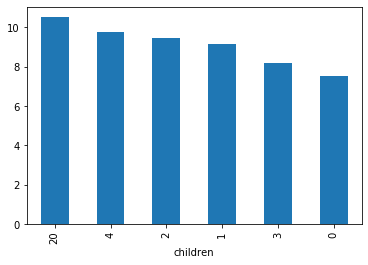

In [97]:
df_1[df_1['всего заёмщиков'] > 9]['доля должников'].plot(kind='bar') # построение графика барплот

**Вывод**

**Зависимость между наличием детей и возвратом кредита в срок установлена.**

Итак, проделав необходимые вычисления, видим, что должников больше среди тех у кого дети есть. 

Должников в категории у кого нет детей : 7,5 %

Должников в категории у кого есть дети : 9,2 %

**3.2 Есть ли зависимость между семейным положением и возвратом кредита в срок?**

Для начала изучим значения в данном столбце - какие есть и в каком количестве.

In [87]:
df['family_status'].value_counts()

женат / замужем          12339
гражданский брак          4151
не женат / не замужем     2810
в разводе                 1195
вдовец / вдова             959
Name: family_status, dtype: int64

In [88]:
df['family_status_id'].value_counts()

0    12339
1     4151
4     2810
3     1195
2      959
Name: family_status_id, dtype: int64

Буду проводить исследование по каждой группе заёмщиков:

In [98]:
df_2 = df.groupby('family_status').agg({'debt': ['count', 'sum', 'mean']}) # применим функции 'count', 'sum', 'mean' для значений
# столбца 'debt' , в разрезе по категориям 'income_type' 

df_2.set_axis(['всего заёмщиков','количество должников','доля должников'],axis = 'columns',inplace = True) # переименовываем столбцы

df_2['доля должников'] *= 100 # простой перевод в проценты

df_2 = df_2.sort_values(by='доля должников', ascending=False) # сортировка таблицы

df_2

,всего заёмщиков,количество должников,доля должников
family_status,,,
не женат / не замужем,2810,274,9.750890
гражданский брак,4151,388,9.347145
женат / замужем,12339,931,7.545182
в разводе,1195,85,7.112971
вдовец / вдова,959,63,6.569343


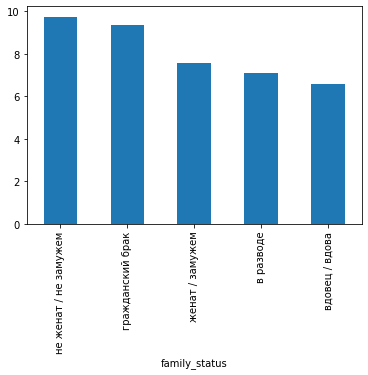

In [99]:
df_2['доля должников'].plot(kind='bar') # построение графика барплот

**Вывод**

**Зависимость между семейным положением и возвратом кредита в срок установлена.**

Самый маленький процент должников среди заёмщиков в категории "вдовец\вдова" - 6,6 %.
Самый большой процент должников среди заёмщиков в категории "не женат / не замужем" - 9,8 %.

Также можно сделать вывод, что среди заёмщиков когда-либо состоящих в браке процент должников меньше - около 7 % в среднем.
А среди заёмщиков "не женат\не замужем" или в "гражданском браке" процент должников намного больше - около 9,5 % в среднем.

**3.3 Есть ли зависимость между уровнем дохода и возвратом кредита в срок?**

Воспользуемся результатом работы в шаге 2.5.2, там я создал датафрейм с категориями по значениям из столбца доход.

Для начала изучим значения в данном столбце - какие есть категории и в каком количестве.

In [ ]:
df_mod['income_group'].value_counts()

расшифровка категорий:

1. 20000-50000
2. 50000-100000
3. 100000-150000
4. 150000-200000
5. 200000-500000
6. 500000-2500000

Буду проводить исследование по каждой категории заёмщиков:

In [100]:
df_3 = df_mod.groupby('income_group').agg({'debt': ['count', 'sum', 'mean']})
df_3.set_axis(['всего заёмщиков','количество должников','доля должников'],axis = 'columns',inplace = True) 
df_3['доля должников'] *= 100 
df_3 = df_3.sort_values(by='доля должников', ascending=False) # сортировка таблицы
df_3

,всего заёмщиков,количество должников,доля должников
income_group,,,
3,7160,624,8.715084
4,4764,405,8.501259
2,4091,331,8.090931
5,4845,344,7.100103
6,222,14,6.306306
1,372,23,6.182796


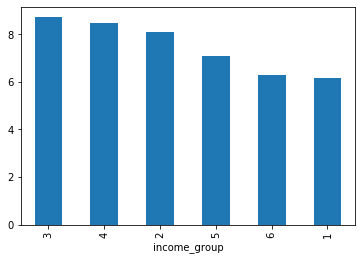

In [101]:
df_3['доля должников'].plot(kind='bar') # построение графика барплот

**Вывод**

Зависимость между уровнем дохода и возвратом кредита в срок - следующая:
при доходе от 20 000 до 200 000 процент должников находится в диапазоне 6 - 9 %  ;
при доходе от 200 000 и выше процент должников падает до 6 %.

Построил столбчатую диаграмму для наглядности.

**3.4 Как разные цели кредита влияют на его возврат в срок?**

Воспользуемся результатом работы в шаге 2.5.1, там я создал датафрейм с категориями по значениям из столбца "цель кредита".

Для начала изучим значения в данном столбце - какие есть категории и в каком количестве.

In [ ]:
df['purpose_group'].value_counts()

Теперь выясню количество должников в процентах по каждой категории.

In [102]:
df_4 = df.groupby('purpose_group').agg({'debt': ['count', 'sum', 'mean']})
df_4.set_axis(['всего заёмщиков','количество должников','доля должников'],axis = 'columns',inplace = True) 
df_4['доля должников'] *= 100 
df_4 = df_4.sort_values(by='доля должников', ascending=False) # сортировка таблицы
df_4

,всего заёмщиков,количество должников,доля должников
purpose_group,,,
покупка автомобиля,4306,403,9.359034
получение образования,4013,370,9.220035
проведение свадьбы,2324,186,8.003442
строительство недвижимости,1878,144,7.667732
покупка коммерческой недвижимости,1311,99,7.551487
покупка недвижимости,7015,504,7.184604
ремонт жилья,607,35,5.766063


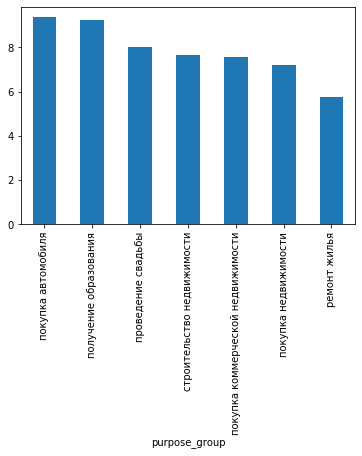

In [103]:
df_4['доля должников'].plot(kind='bar') # построение графика барплот

**Вывод**

Чаще всего кредит возвращают в срок заёмщики с целями : покупка или строительство недвижимости, 
ремонт жилья - процент должников примерно 7 %.

В остальных категориях: покупка автомобиля, получение образования, свадьба - процент должников выше - около 9 %.

## Шаг 4. Общий вывод

Мною было проведено исследование на основе статистических данных заёмщиков, в ходе которого удалось выяснить:

1. Есть ли зависимость между наличием детей и возвратом кредита в срок?
2. Есть ли зависимость между семейным положением и возвратом кредита в срок?
3. Есть ли зависимость между уровнем дохода и возвратом кредита в срок?
4. Как разные цели кредита влияют на его возврат в срок? 
